# Reconstruction pipeline

This notebook demonstrates the modular reconstruction pipeline used to turn raw k-space
data into images.

The standard Cartesian pipeline is NumPy-first (and JAX-compatible) and includes stages like zero filling, FFT,
homodyne, and POCS (data consistency). Variational reconstruction is covered separately in
`variational_reconstruction.ipynb`.

The examples below use small synthetic data and do not require vendor files.

k-space in -> (1, 32, 32), reconstructed image -> (1, 32, 32)


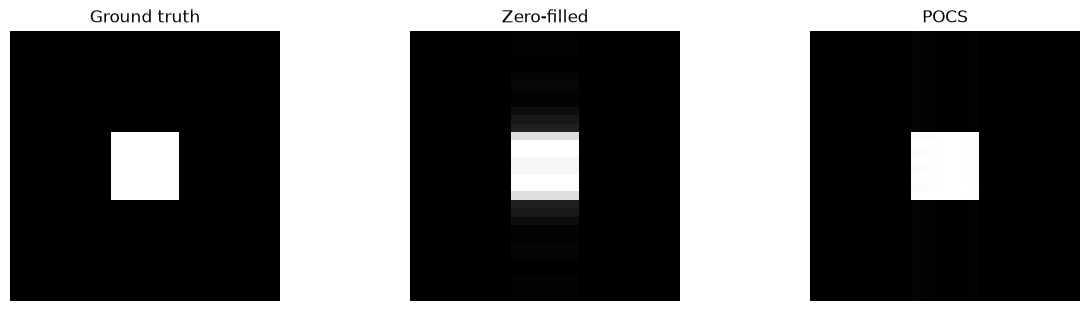

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from mrax.reco.pipeline import (
    FFTStage,
    POCSStage,
    RecoPipeline,
    ZeroFillStage,
    cartesian_fft,
    cartesian_ifft,
)

# Synthetic object and fully-sampled k-space
time_series = np.zeros((1, 32, 32), dtype=np.float32)
time_series[0, 12:20, 12:20] = 1.0
kspace_full = cartesian_fft(time_series)

# Partial Fourier undersampling (PF=0.75): keep the last 3/4 of ky lines.
mask = np.zeros((32, 32), dtype=bool)
mask[8:, :] = True
undersampled = kspace_full * mask[None, ...]

# Baseline: zero-filled inverse FFT.
zf_img = np.abs(cartesian_ifft(undersampled))[0]

# Chain together modular reconstruction blocks (NumPy-first; accepts JAX arrays).
pipeline = RecoPipeline(
    [
        ZeroFillStage(target_shape=(32, 32)),
        POCSStage(iterations=20),
        FFTStage(direction="inverse"),
    ]
)

state = pipeline.run(undersampled, metadata={"mask": mask})
reco_img = np.abs(state.image)[0]
print(f"k-space in -> {undersampled.shape}, reconstructed image -> {state.image.shape}")

vmax = float(np.max(time_series))
fig, axes = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
axes[0].imshow(time_series[0], cmap="gray", vmin=0, vmax=vmax)
axes[0].set_title("Ground truth")
axes[1].imshow(zf_img, cmap="gray", vmin=0, vmax=vmax)
axes[1].set_title("Zero-filled")
axes[2].imshow(reco_img, cmap="gray", vmin=0, vmax=vmax)
axes[2].set_title("POCS")
for ax in axes:
    ax.axis("off")
plt.show()


### JAX IFFT sanity check

A simple centered, orthonormal IFFT can also be run with JAX (CPU/GPU) using `cartesian_ifft_jax`.


Max abs diff (NumPy vs JAX IFFT): 1.551e-07


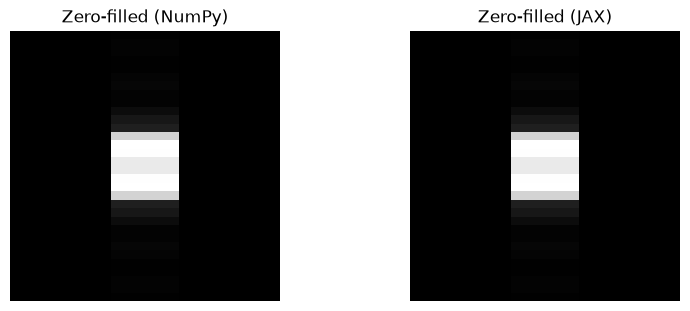

In [2]:
import jax.numpy as jnp

from mrax.reco.jax_fft import cartesian_ifft_jax

zf_np = cartesian_ifft(undersampled)[0]
zf_jax = np.asarray(cartesian_ifft_jax(jnp.asarray(undersampled)))[0]

print(f"Max abs diff (NumPy vs JAX IFFT): {np.max(np.abs(zf_np - zf_jax)):.3e}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
axes[0].imshow(np.abs(zf_np), cmap="gray")
axes[0].set_title("Zero-filled (NumPy)")
axes[1].imshow(np.abs(zf_jax), cmap="gray")
axes[1].set_title("Zero-filled (JAX)")
for ax in axes:
    ax.axis("off")
plt.show()
